In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
sns.set_palette('pastel')



In [3]:
df_student = pd.read_csv('student_lifestyle_dataset.csv')


In [4]:
print("Shape:", df_student.shape)
print("Columns:", df_student.columns.tolist())
print("\nHead:\n", df_student.head())
print("\nInfo:")
df_student.info()
print("\nDescribe:\n", df_student.describe())
print("\nMissing values:\n", df_student.isnull().sum())

# Identify columns dynamically to be accurate
cols = df_student.columns.tolist()

Shape: (100, 7)
Columns: ['student_id', 'gender', 'study_hours', 'sleep_hours', 'screen_time', 'internet_usage', 'daily_transport_cost']

Head:
   student_id  gender  study_hours  sleep_hours  screen_time  internet_usage  \
0       S001  Female          7.0          7.1          2.7             9.3   
1       S002  Female          4.9          6.9          2.9             1.0   
2       S003  Female          5.9          8.9          5.3             5.2   
3       S004  Female          3.2          4.2          1.8             5.2   
4       S005    Male          1.8          5.0          2.5             6.1   

   daily_transport_cost  
0                 102.0  
1                 284.0  
2                 123.0  
3                  73.0  
4                 202.0  

Info:
<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   student_id        

In [5]:
# Q1: What is the average number of study hours?
study_col = [c for c in cols if 'study' in c.lower()][0]
avg_study = df_student[study_col].mean()
print(f"\nQ1 ({study_col}) - mean: {avg_study:.4f}, median: {df_student[study_col].median():.4f}, std: {df_student[study_col].std():.4f}, min: {df_student[study_col].min()}, max: {df_student[study_col].max()}")


Q1 (study_hours) - mean: 4.4030, median: 4.3000, std: 2.0139, min: 1.1, max: 7.8


In [6]:
# Q2: Who sleeps more on average - males or females?
sleep_col = [c for c in cols if 'sleep' in c.lower()][0]
gender_col = [c for c in cols if 'gender' in c.lower()][0]
sleep_by_gender = df_student.groupby(gender_col)[sleep_col].agg(['count', 'mean', 'median', 'std', 'min', 'max'])
print(f"\nQ2 ({sleep_col} by {gender_col}):\n", sleep_by_gender)


Q2 (sleep_hours by gender):
         count      mean  median       std  min  max
gender                                             
Female     52  6.796154     6.9  1.504368  4.0  9.0
Male       48  6.389583     6.3  1.469873  4.1  8.9



Q3 (Correlation screen_time vs sleep_hours):
              screen_time  sleep_hours
screen_time     1.000000     0.052386
sleep_hours     0.052386     1.000000


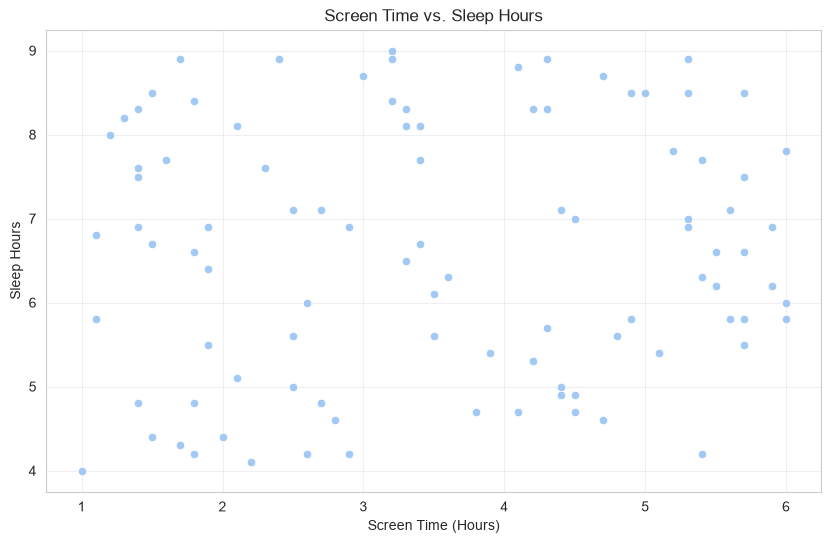

In [7]:
# Q3: Is there a relationship between screen time and sleep hours?
screen_col = [c for c in cols if 'screen' in c.lower()][0]
corr_matrix = df_student[[screen_col, sleep_col]].corr()
print(f"\nQ3 (Correlation {screen_col} vs {sleep_col}):\n", corr_matrix)
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_student, x=screen_col, y=sleep_col)
plt.title('Screen Time vs. Sleep Hours')
plt.xlabel('Screen Time (Hours)')
plt.ylabel('Sleep Hours')
plt.grid(True, alpha=0.3)
plt.savefig('q3_screen_vs_sleep.png', dpi=300, bbox_inches='tight')
plt.show()


Q4 (daily_transport_cost) stats - mean: 168.26, median: 169.50, std: 76.24, min: 50.0, max: 298.0


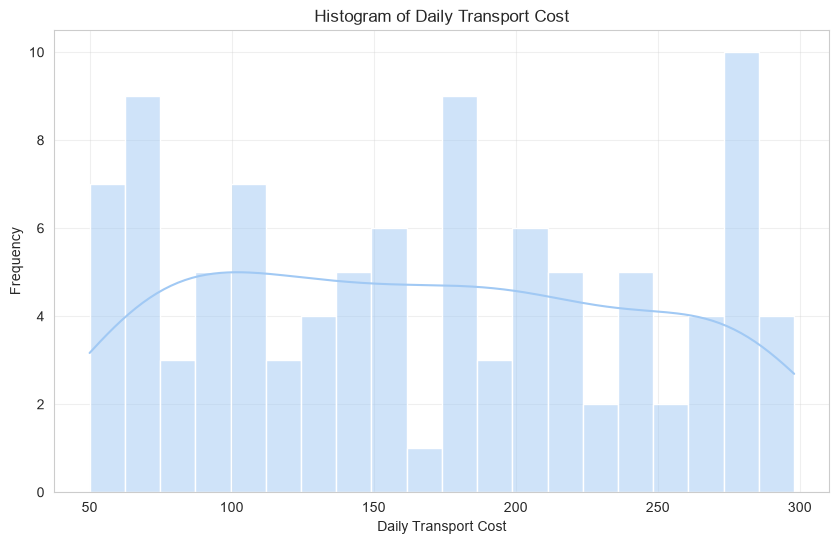

In [8]:
# Q4: Draw a histogram of daily transport cost.
transport_col = [c for c in cols if 'transport' in c.lower()][0]
print(f"\nQ4 ({transport_col}) stats - mean: {df_student[transport_col].mean():.2f}, median: {df_student[transport_col].median():.2f}, std: {df_student[transport_col].std():.2f}, min: {df_student[transport_col].min()}, max: {df_student[transport_col].max()}")

plt.figure(figsize=(10, 6))
sns.histplot(data=df_student, x=transport_col, bins=20, kde=True)
plt.title('Histogram of Daily Transport Cost')
plt.xlabel('Daily Transport Cost')
plt.ylabel('Frequency')
plt.grid(True, alpha=0.3)
plt.savefig('q4_transport_cost_hist.png', dpi=300, bbox_inches='tight')
plt.show()


Q5 (internet_usage by gender):
         count      mean  median       std  min  max
gender                                             
Female     52  5.321154    5.35  2.774982  1.0  9.9
Male       48  6.002083    5.90  2.415507  1.6  9.9


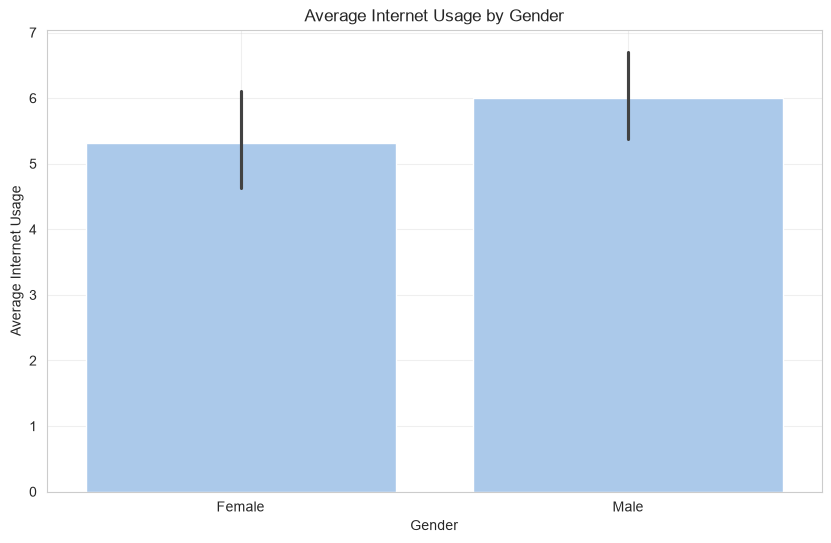

In [9]:
# Q5: Compare average internet usage by gender.
internet_col = [c for c in cols if 'internet' in c.lower()][0]
internet_by_gender = df_student.groupby(gender_col)[internet_col].agg(['count', 'mean', 'median', 'std', 'min', 'max'])
print(f"\nQ5 ({internet_col} by {gender_col}):\n", internet_by_gender)

plt.figure(figsize=(10, 6))
sns.barplot(data=df_student, x=gender_col, y=internet_col, estimator='mean')
plt.title('Average Internet Usage by Gender')
plt.xlabel('Gender')
plt.ylabel('Average Internet Usage')
plt.grid(True, alpha=0.3)
plt.savefig('q5_internet_by_gender.png', dpi=300, bbox_inches='tight')
plt.show()